# Практикум по основам статистики

Цель практикума — научиться загружать табличные данные, описывать распределения, строить графики, сравнивать группы, изучать связи между переменными и формулировать выводы по результатам статистических тестов.

## Как работать с ноутбуком
1. Поместите свой CSV-файл в ту же папку, где лежит этот ноутбук.
2. В ячейке загрузки укажите имя файла в переменной `filename`.
3. Выполните ячейки сверху вниз. После загрузки проверьте автоматически выбранные столбцы и при необходимости замените их на свои.
4. В каждом задании запишите собственный результат и содержательный вывод.

В ноутбуке используются `pandas`, `numpy`, `matplotlib`, `seaborn` и `scipy.stats`. Предполагается, что CSV содержит хотя бы один числовой и один категориальный столбец.

In [54]:

%pip install numpy pandas matplotlib seaborn scipy
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

Note: you may need to restart the kernel to use updated packages.


In [55]:
# Показываем доступные CSV-файлы в папке с ноутбуком.
datasets_dir = "."
csv_files = sorted([
    file for file in os.listdir(datasets_dir)
    if file.lower().endswith(".csv")
]) if os.path.isdir(datasets_dir) else []
print("Доступные CSV-файлы:")
print(csv_files if csv_files else "Файлы не найдены: добавьте CSV в папку с ноутбуком.")


Доступные CSV-файлы:
['cars.csv']


In [56]:
# ← ЗАМЕНИТЕ НА СВОЁ: имя CSV-файла из списка выше.
filename = "cars.csv"
# В cars.csv разделитель — «;», а вторая строка содержит типы столбцов (STRING;DOUBLE;...), её пропускаем.
df = pd.read_csv(os.path.join(datasets_dir, filename), sep=";", skiprows=[1])

print("Первые строки:")
display(df.head())
print("Информация о данных:")
df.info()
print(f"Размер датафрейма: {df.shape}")


Первые строки:


,Car,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model,Origin
0,Chevrolet Chevelle Malibu,18.0,8,307.0,130.0,3504.0,12.0,70,US
1,Buick Skylark 320,15.0,8,350.0,165.0,3693.0,11.5,70,US
2,Plymouth Satellite,18.0,8,318.0,150.0,3436.0,11.0,70,US
3,AMC Rebel SST,16.0,8,304.0,150.0,3433.0,12.0,70,US
4,Ford Torino,17.0,8,302.0,140.0,3449.0,10.5,70,US


Информация о данных:
<class 'pandas.DataFrame'>
RangeIndex: 406 entries, 0 to 405
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car           406 non-null    str    
 1   MPG           406 non-null    float64
 2   Cylinders     406 non-null    int64  
 3   Displacement  406 non-null    float64
 4   Horsepower    406 non-null    float64
 5   Weight        406 non-null    float64
 6   Acceleration  406 non-null    float64
 7   Model         406 non-null    int64  
 8   Origin        406 non-null    str    
dtypes: float64(5), int64(2), str(2)
memory usage: 28.7 KB
Размер датафрейма: (406, 9)


### Проверка качества данных

В `cars.csv` пропуски закодированы нулями: у части автомобилей `MPG` и `Horsepower` равны `0`, что физически невозможно. Заменяем такие нули на `NaN`, чтобы они не искажали статистики (методы pandas пропуски игнорируют).

In [57]:
# Нули в MPG и Horsepower — это пропуски, а не реальные значения.
zero_cols = ["MPG", "Horsepower"]
print("Нулевых значений до очистки:")
print((df[zero_cols] == 0).sum())

df[zero_cols] = df[zero_cols].replace(0, np.nan)

print("\nПропусков после очистки:")
print(df.isna().sum())
print(f"\nПолных дубликатов строк: {df.duplicated().sum()}")


Нулевых значений до очистки:
MPG           8
Horsepower    6
dtype: int64

Пропусков после очистки:
Car             0
MPG             8
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model           0
Origin          0
dtype: int64

Полных дубликатов строк: 0


In [58]:
# Подготавливаем универсальные имена столбцов для следующих примеров.
coll = df.select_dtypes(include=np.number).columns.tolist()
# Категориальные столбцы: исключаем «идентификаторы» с большим числом уникальных значений (название машины).
categorical_columns = [
    c for c in df.select_dtypes(exclude=np.number).columns
    if df[c].nunique() <= 20
]
if not coll:
    raise ValueError("В датасете нужен хотя бы один числовой столбец.")
column = coll[0]
col1 = coll[0]
col2 = coll[1] if len(coll) > 1 else coll[0]
cat_column = categorical_columns[0] if categorical_columns else None
if cat_column is None:
    df["_category"] = pd.qcut(df[column], q=3, duplicates="drop").astype(str)
    cat_column = "_category"

print("Числовые столбцы:", coll)
print("Категориальный столбец для примеров:", cat_column)
print("Основной числовой столбец:", column)


Числовые столбцы: ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model']
Категориальный столбец для примеров: Origin
Основной числовой столбец: MPG


# Раздел 1. Описательная статистика

### `df.describe()` — общая сводка

**Что делает:**** Возвращает основные описательные статистики числовых столбцов: число наблюдений, среднее, стандартное отклонение, квартили, минимум и максимум.

**Синтаксис:** `df.describe(include=None, percentiles=None)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `include` | Типы данных, которые нужно включить, например `"all"`. |
| `percentiles` | Список дополнительных квантилей от 0 до 1. |

In [59]:
# Получаем сводку по числовым столбцам датасета.
display(df.describe())

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model
count,398.000000,406.000000,406.000000,400.000000,406.000000,406.000000,406.000000
mean,23.514573,5.475369,194.779557,105.082500,2979.413793,15.519704,75.921182
std,7.815984,1.712160,104.922458,38.768779,847.004328,2.803359,3.748737
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,105.000000,75.750000,2226.500000,13.700000,73.000000
50%,23.000000,4.000000,151.000000,95.000000,2822.500000,15.500000,76.000000
75%,29.000000,8.000000,302.000000,130.000000,3618.250000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` получите сводку с дополнительными квантилями и опишите, какие столбцы имеют наибольший разброс.

### `df[col].mean()`, `.median()`, `.mode()` — меры центральной тенденции

**Что делает:**** Среднее показывает арифметический центр, медиана делит упорядоченные данные пополам, а мода возвращает наиболее частое значение. Медиана и мода обычно устойчивее к выбросам, чем среднее.

**Синтаксис:** `df[col].mean()`, `df[col].median()`, `df[col].mode()`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `col` | Имя анализируемого столбца. |
| `skipna` | Пропускать ли пропущенные значения. |

In [60]:
# Сравниваем три меры центра для выбранного числового столбца.
print("Среднее:", df[coll].mean())
print("Медиана:", df[coll].median())
print("Мода:")
display(df[coll].mode())

Среднее: MPG               23.514573
Cylinders          5.475369
Displacement     194.779557
Horsepower       105.082500
Weight          2979.413793
Acceleration      15.519704
Model             75.921182
dtype: float64
Медиана: MPG               23.0
Cylinders          4.0
Displacement     151.0
Horsepower        95.0
Weight          2822.5
Acceleration      15.5
Model             76.0
dtype: float64
Мода:


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model
0,13.0,4.0,97.0,150.0,1985.0,14.5,73.0
1,NaN,NaN,NaN,NaN,2130.0,NaN,NaN


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` выберите другой числовой столбец, вычислите три меры центра и объясните, почему они различаются или совпадают.

### `df[col].std()`, `.var()`, `.min()`, `.max()` — меры разброса

**Что делает:**** Эти методы описывают изменчивость данных: стандартное отклонение и дисперсия измеряют разброс относительно среднего, а минимум и максимум задают границы наблюдений.

**Синтаксис:** `df[col].std()`, `df[col].var()`, `df[col].min()`, `df[col].max()`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `col` | Имя числового столбца. |
| `ddof` | Поправка числа степеней свободы для дисперсии и стандартного отклонения. |
| `skipna` | Исключать ли пропуски. |

In [61]:
# Рассчитываем диапазон и вариативность значений.
spread = pd.Series({
    "std": df[coll[2]].std(),
    "var": df[coll[2]].var(),
    "min": df[coll[2]].min(),
    "max": df[coll[2]].max(),
})
display(spread)

std      104.922458
var    11008.722272
min       68.000000
max      455.000000
dtype: float64

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` сравните разброс двух числовых столбцов и укажите, какой из них изменяется сильнее.

### `df[col].quantile([0.25, 0.5, 0.75])` — квартили

**Что делает:**** Вычисляет значения, ниже которых находится заданная доля наблюдений. Квартили 0.25, 0.5 и 0.75 образуют основу анализа медианы и межквартильного размаха.

**Синтаксис:** `df[col].quantile([0.25, 0.5, 0.75])`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `q` | Одно число или список квантилей от 0 до 1. |
| `interpolation` | Способ интерполяции между соседними значениями. |

In [62]:
# Находим первый, второй и третий квартили.
quartiles = df[column].quantile([0.25, 0.5, 0.75])
print(quartiles)
print("Межквартильный размах:", quartiles.loc[0.75] - quartiles.loc[0.25])


0.25    17.5
0.50    23.0
0.75    29.0
Name: MPG, dtype: float64
Межквартильный размах: 11.5


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` найдите квартили для другого столбца и определите интервал, в котором лежит центральные 50% наблюдений.

In [63]:
quartiles = df[coll[3]].quantile([0.25, 0.5, 0.75])
print(quartiles)
print(coll[3])
q1 = df[coll[3]].quantile(0.25)
q3 = df[coll[3]].quantile(0.75)
iqr = q3 - q1
print(f"Центральные 50% наблюдений лежат в интервале: [{q1:.2f}; {q3:.2f}]")
print(f"IQR = {iqr:.2f}")

0.25     75.75
0.50     95.00
0.75    130.00
Name: Horsepower, dtype: float64
Horsepower
Центральные 50% наблюдений лежат в интервале: [75.75; 130.00]
IQR = 54.25


### `df[col].skew()`, `.kurt()` — форма распределения

**Что делает:**** `skew()` оценивает асимметрию распределения, а `kurt()` — его эксцесс относительно нормального распределения. Знак и величина показателей помогают заметить длинный хвост или необычную концентрацию значений.

**Синтаксис:** `df[col].skew()`, `df[col].kurt()`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `axis` | Ось вычисления. |
| `skipna` | Игнорировать ли пропуски. |
| `numeric_only` | Использовать только числовые данные. |

In [64]:
# Оцениваем асимметрию и эксцесс выбранного столбца.
print("Асимметрия:", df[column].skew())
print("Эксцесс:", df[column].kurt())

Асимметрия: 0.45706634399492074
Эксцесс: -0.5107812652123145


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` вычислите асимметрию и эксцесс для двух столбцов и сопоставьте их с формой гистограмм.

--- Horsepower ---
Асимметрия (skew): 1.034
Эксцесс (kurt):    0.541

--- Weight ---
Асимметрия (skew): 0.506
Эксцесс (kurt):    -0.821



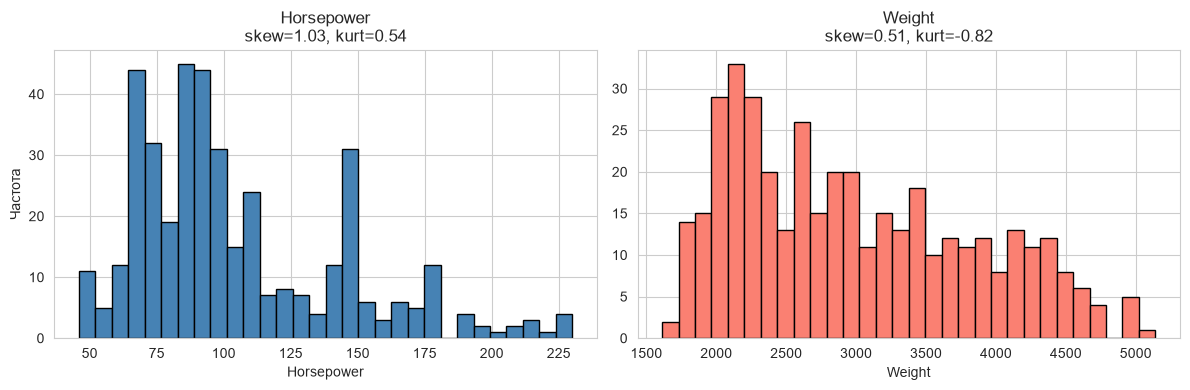

In [65]:
col1 = coll[3]   # Horsepower
col2 = coll[4]   # Weight

for col in [col1, col2]:
    print(f"--- {col} ---")
    print(f"Асимметрия (skew): {df[col].skew():.3f}")
    print(f"Эксцесс (kurt):    {df[col].kurt():.3f}")
    print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df[col1].dropna(), bins=30, color="steelblue", edgecolor="black")
axes[0].set_title(f"{col1}\nskew={df[col1].skew():.2f}, kurt={df[col1].kurt():.2f}")
axes[0].set_xlabel(col1)
axes[0].set_ylabel("Частота")

axes[1].hist(df[col2].dropna(), bins=30, color="salmon", edgecolor="black")
axes[1].set_title(f"{col2}\nskew={df[col2].skew():.2f}, kurt={df[col2].kurt():.2f}")
axes[1].set_xlabel(col2)

plt.tight_layout()
plt.show()


### `df[col].value_counts()` — частоты категорий

**Что делает:**** Подсчитывает количество вхождений каждого уникального значения. Метод особенно полезен для категориальных переменных и позволяет быстро увидеть редкие категории.

**Синтаксис:** `df[col].value_counts(normalize=False, dropna=True)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `normalize` | Вернуть доли вместо абсолютных частот. |
| `sort` | Сортировать ли результат. |
| `dropna` | Учитывать ли пропуски. |

In [66]:
# Считаем абсолютные и относительные частоты категорий.
display(df[cat_column].value_counts(dropna=False).head(10))
display(df[cat_column].value_counts(normalize=True, dropna=False).head(10))

Origin
US        254
Japan      79
Europe     73
Name: count, dtype: int64

Origin
US        0.625616
Japan     0.194581
Europe    0.179803
Name: proportion, dtype: float64

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` найдите частоты для своей категориальной переменной и оцените, есть ли дисбаланс классов.

In [67]:

# Абсолютные частоты
counts = df[cat_column].value_counts(dropna=False)
print("Абсолютные частоты:")
display(counts)

# Относительные частоты (доли)
proportions = df[cat_column].value_counts(normalize=True, dropna=False)
print("\nОтносительные частоты:")
display(proportions.round(3))

Абсолютные частоты:


Origin
US        254
Japan      79
Europe     73
Name: count, dtype: int64


Относительные частоты:


Origin
US        0.626
Japan     0.195
Europe    0.180
Name: proportion, dtype: float64

# Раздел 2. Визуализация распределений

### `sns.histplot()` — гистограмма с KDE

**Что делает:**** Строит столбчатое представление распределения числовых данных. Параметр `kde=True` добавляет сглаженную оценку плотности.

**Синтаксис:** `sns.histplot(data=df, x=column, bins=20, kde=True)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Датафрейм с данными. |
| `x` | Числовой столбец по оси X. |
| `bins` | Число интервалов. |
| `kde` | Добавить ли кривую плотности. |

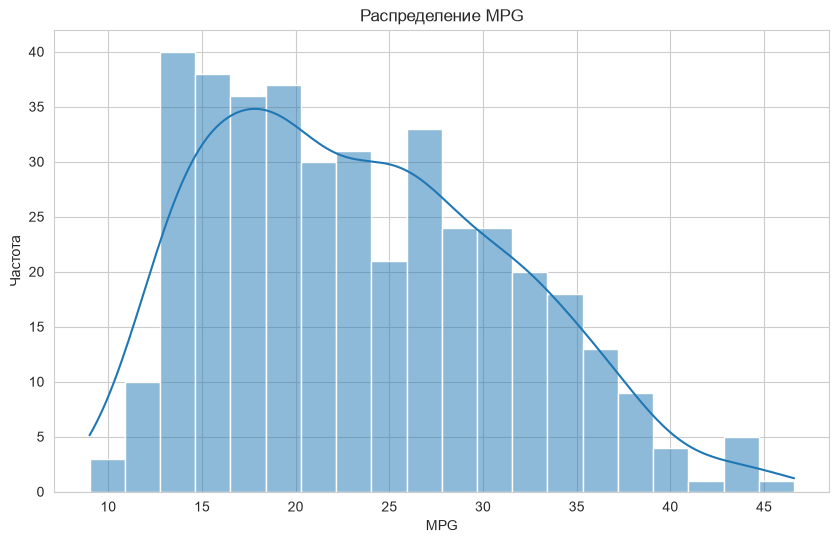

In [68]:
# Строим гистограмму с оценкой плотности.
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x=column, bins=20, kde=True)
plt.title(f"Распределение {column}")
plt.xlabel(column)
plt.ylabel("Частота")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` измените число интервалов, постройте гистограмму другого числового столбца и опишите форму распределения.

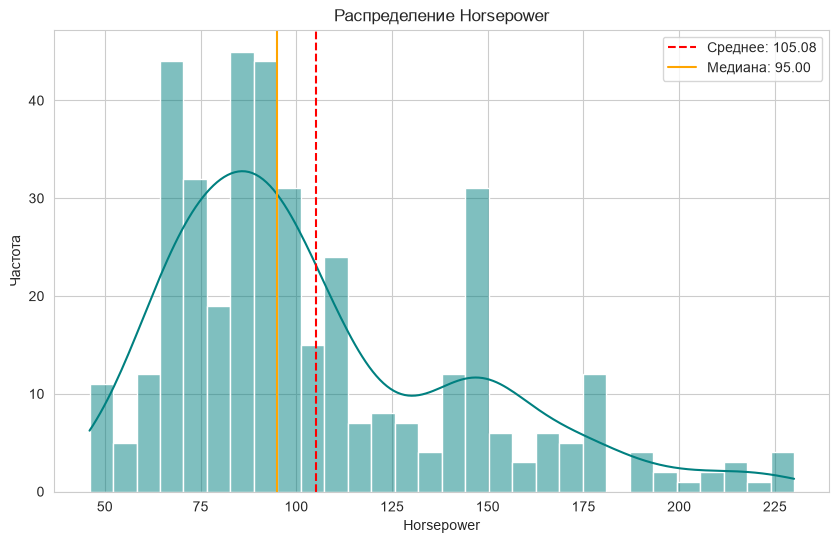

Асимметрия: 1.03
Эксцесс: 0.54


In [69]:


plt.figure(figsize=(10, 6))
sns.histplot(data=df, x=coll[3], bins=30, kde=True, color="teal")

mean_val = df[coll[3]].mean()
median_val = df[coll[3]].median()
plt.axvline(mean_val, color='red', linestyle='--', label=f'Среднее: {mean_val:.2f}')
plt.axvline(median_val, color='orange', linestyle='-', label=f'Медиана: {median_val:.2f}')

plt.title(f"Распределение {coll[3]}")
plt.xlabel(coll[3])
plt.ylabel("Частота")
plt.legend()
plt.show()

print(f"Асимметрия: {df[coll[3]].skew():.2f}")
print(f"Эксцесс: {df[coll[3]].kurt():.2f}")

### `sns.boxplot()` — ящик с усами

**Что делает:**** Показывает медиану, квартили, межквартильный размах и потенциальные выбросы числовой переменной.

**Синтаксис:** `sns.boxplot(data=df, y=column)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Датафрейм. |
| `x`, `y` | Переменная по горизонтали или вертикали. |
| `showfliers` | Показывать ли выбросы. |

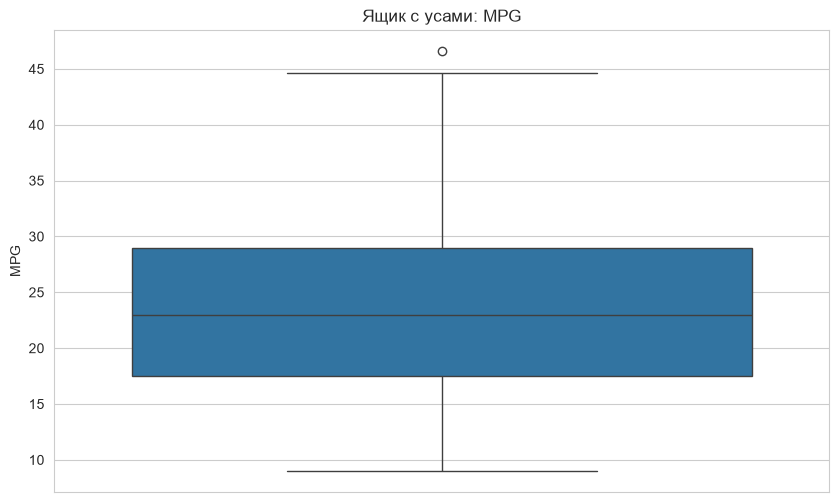

In [70]:
# Визуализируем квартили и потенциальные выбросы.
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, y=column)
plt.title(f"Ящик с усами: {column}")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` постройте boxplot для другого столбца и перечислите наблюдения, которые могут быть выбросами.

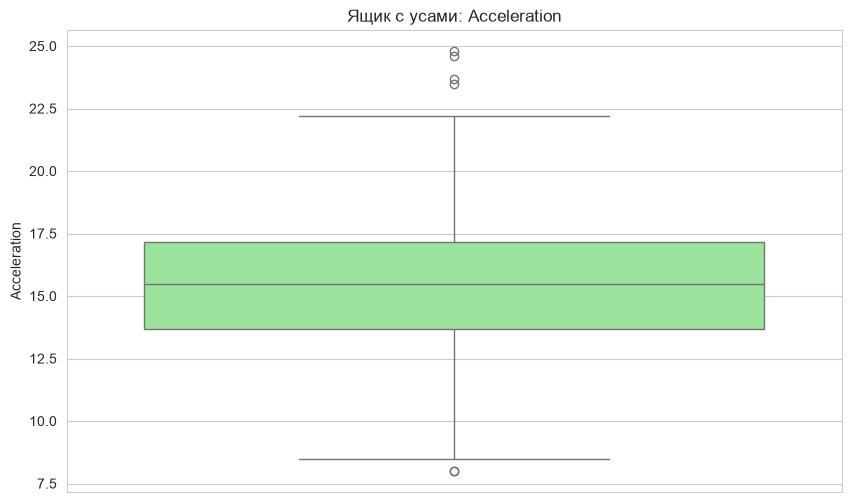

In [71]:

column = coll[5]

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, y=column, color="lightgreen")
plt.title(f"Ящик с усами: {column}")
plt.show()

### `sns.violinplot()` — скрипичная диаграмма

**Что делает:**** Совмещает идею boxplot с оценкой плотности, поэтому показывает не только квартили, но и форму распределения.

**Синтаксис:** `sns.violinplot(data=df, y=column, inner="box")`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Датафрейм. |
| `x`, `y` | Анализируемая переменная. |
| `inner` | Внутреннее отображение, например `"box"` или `"quartile"`. |

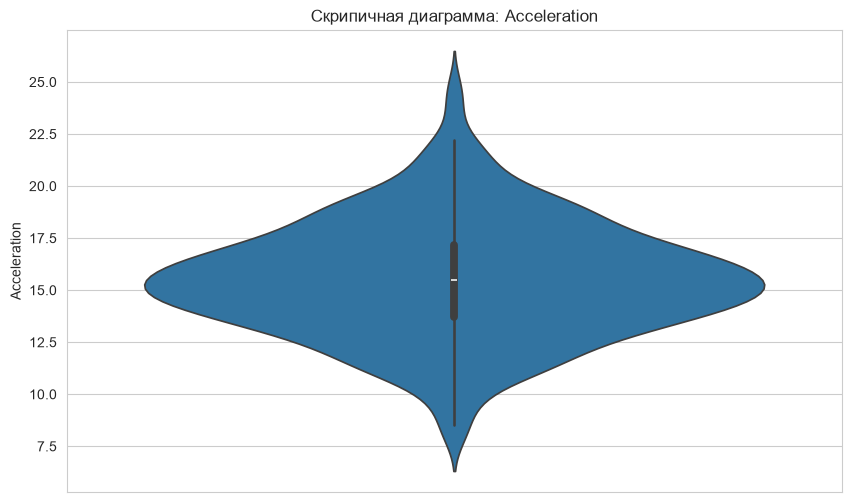

In [72]:
# Показываем плотность и квартили одновременно.
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, y=column, inner="box")
plt.title(f"Скрипичная диаграмма: {column}")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` сравните violinplot и boxplot одного столбца и объясните, какую дополнительную информацию даёт плотность.

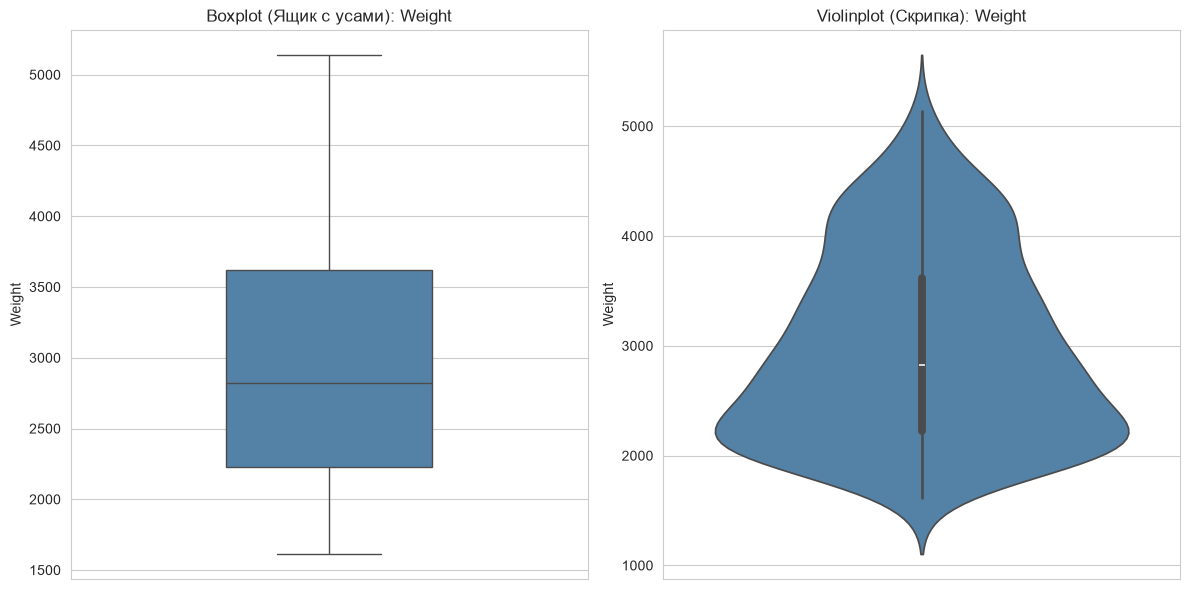

In [73]:
column = coll[4]   # Weight
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.boxplot(data=df, y=column, ax=axes[0], color="steelblue", width=0.4)
axes[0].set_title(f"Boxplot (Ящик с усами): {column}")
sns.violinplot(data=df, y=column, ax=axes[1], color="steelblue", inner="box")
axes[1].set_title(f"Violinplot (Скрипка): {column}")
plt.tight_layout()
plt.show()


### `sns.kdeplot()` — ядерная оценка плотности

**Что делает:**** Оценивает непрерывную плотность распределения без дискретных столбиков гистограммы. Параметр `fill=True` закрашивает область под кривой.

**Синтаксис:** `sns.kdeplot(data=df, x=column, fill=True)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Датафрейм. |
| `x` | Числовой столбец. |
| `fill` | Заполнить область под кривой. |
| `bw_adjust` | Масштаб сглаживания. |

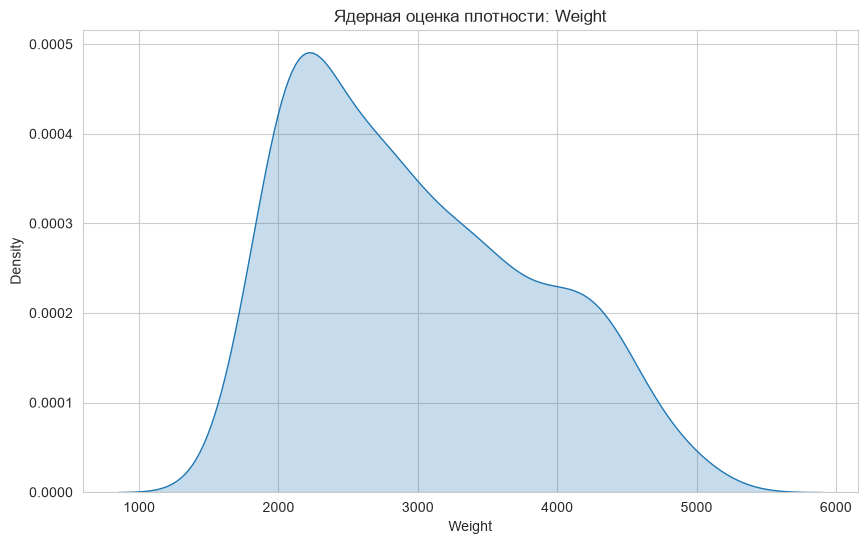

In [74]:
# Строим сглаженную оценку плотности.
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x=column, fill=True)
plt.title(f"Ядерная оценка плотности: {column}")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` измените `bw_adjust`, сравните степень сглаживания и выберите наиболее информативный вариант.

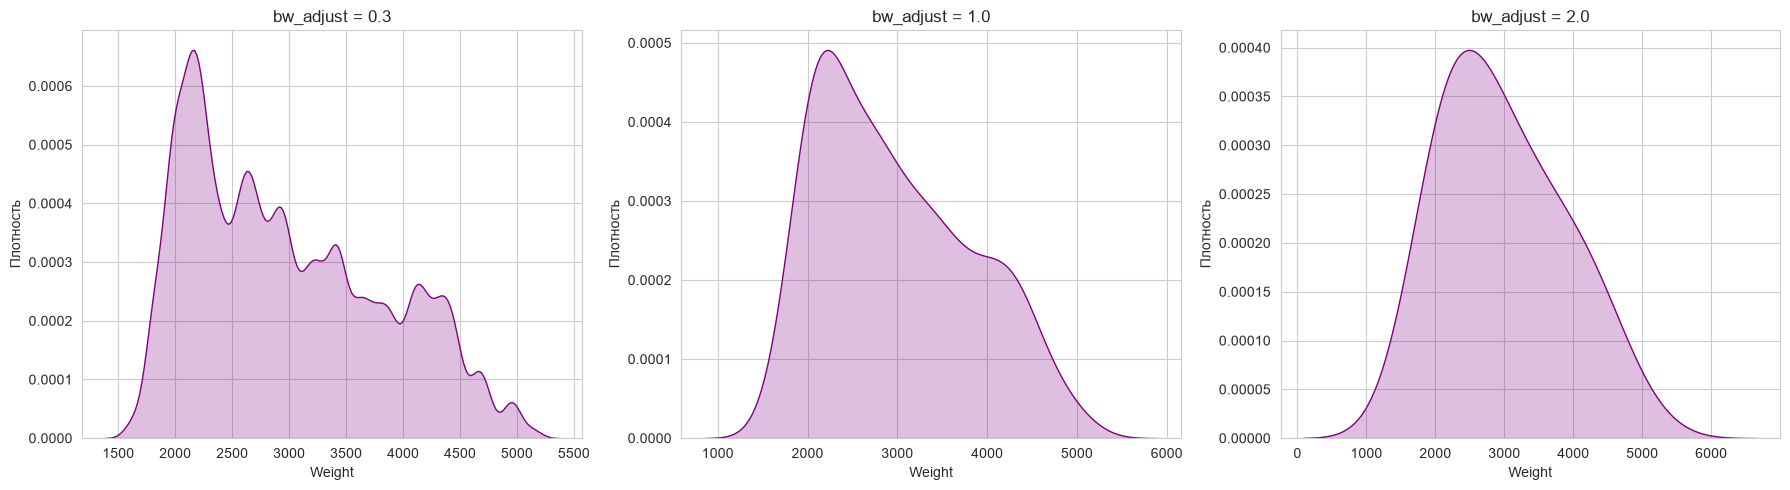

In [75]:
bw_values = [0.3, 1.0, 2.0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, bw in zip(axes, bw_values):
    sns.kdeplot(data=df, x=column, fill=True, bw_adjust=bw, ax=ax, color="purple")

    ax.set_title(f"bw_adjust = {bw}")
    ax.set_xlabel(column)
    ax.set_ylabel("Плотность")

plt.tight_layout()
plt.show()

### `plt.axvline()` — линии среднего и медианы

**Что делает:**** Добавляет вертикальную линию на текущий график. Это удобно для обозначения среднего, медианы, порога или другого фиксированного значения.

**Синтаксис:** `plt.axvline(x=value, color="red", linestyle="--", label="Подпись")`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `x` | Координата вертикальной линии. |
| `color` | Цвет линии. |
| `linestyle` | Стиль линии. |
| `label` | Подпись в легенде. |

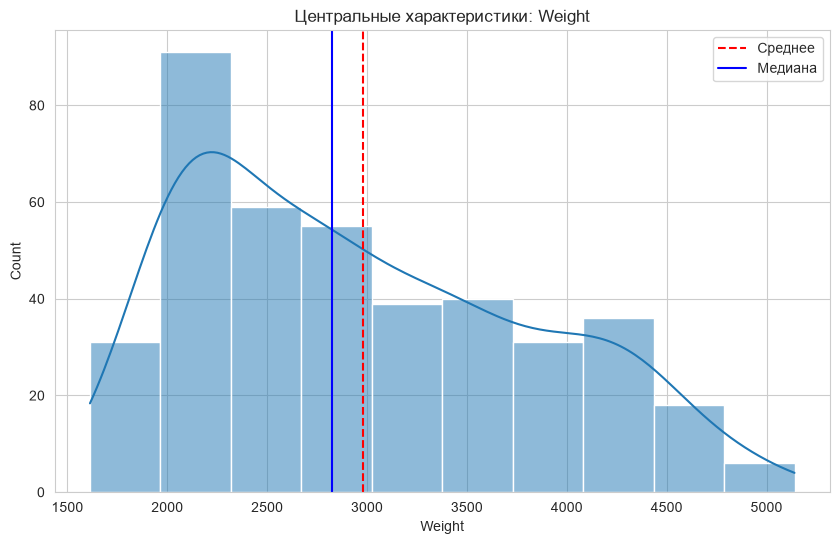

In [76]:
# Добавляем среднее и медиану к гистограмме.
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x=column, kde=True)
plt.axvline(df[column].mean(), color="red", linestyle="--", label="Среднее")
plt.axvline(df[column].median(), color="blue", linestyle="-", label="Медиана")
plt.legend()
plt.title(f"Центральные характеристики: {column}")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` добавьте линию выбранного порога и интерпретируйте положение среднего относительно медианы.

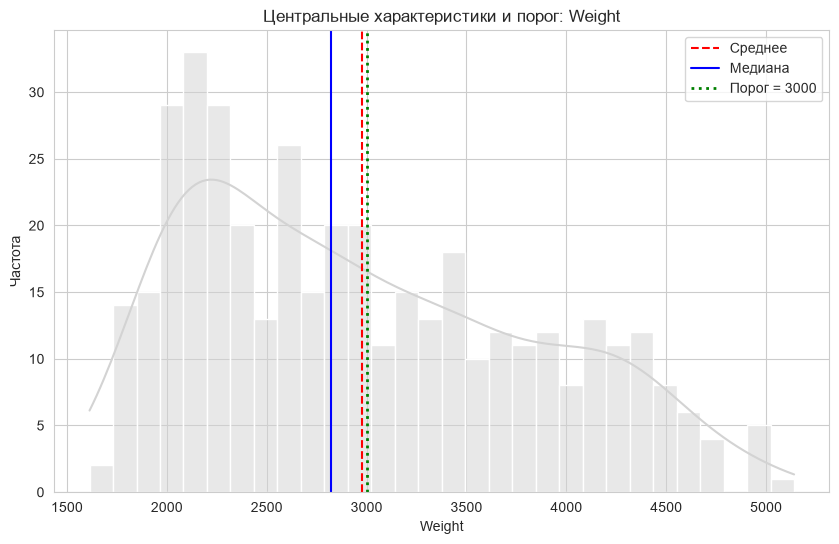

In [77]:
threshold_value = 3000   # ориентир: вес 3000 фунтов (~1360 кг)
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x=column, bins=30, kde=True, color="lightgray")

plt.axvline(df[column].mean(), color="red", linestyle="--", label="Среднее")
plt.axvline(df[column].median(), color="blue", linestyle="-", label="Медиана")

plt.axvline(threshold_value, color="green", linestyle=":", linewidth=2, label=f"Порог = {threshold_value}")

plt.legend()
plt.title(f"Центральные характеристики и порог: {column}")
plt.xlabel(column)
plt.ylabel("Частота")
plt.show()


# Раздел 3. Сравнение групп

### `sns.boxplot(x=cat_col, y=num_col, data=df)` — распределения по группам

**Что делает:**** Сопоставляет медианы, квартили и выбросы числовой переменной между категориями. Это базовый способ визуально оценить различия групп.

**Синтаксис:** `sns.boxplot(x=cat_col, y=num_col, data=df)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `x` | Категориальная переменная группировки. |
| `y` | Числовая переменная. |
| `data` | Датафрейм. |
| `order` | Желаемый порядок категорий. |

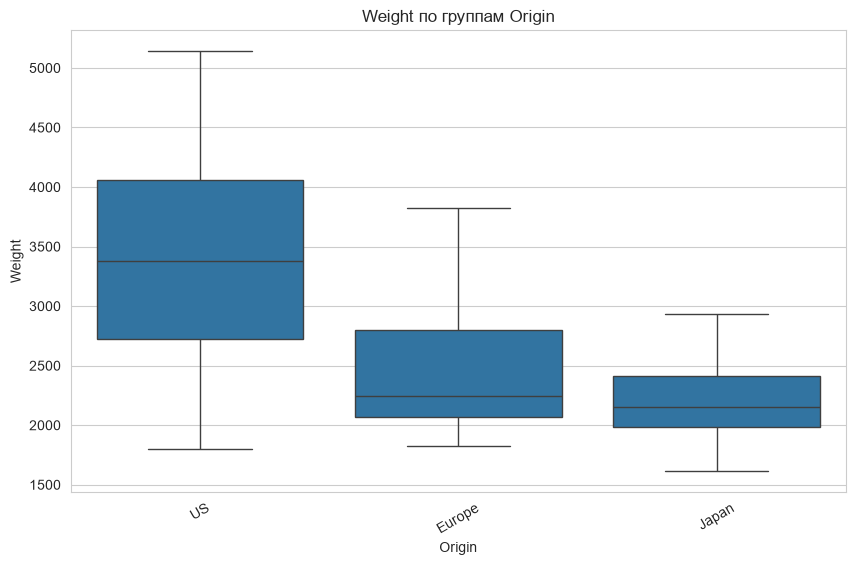

In [78]:
# Сравниваем распределение числового столбца между категориями.
plt.figure(figsize=(10, 6))
sns.boxplot(x=cat_column, y=column, data=df)
plt.xticks(rotation=30)
plt.title(f"{column} по группам {cat_column}")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` выберите другую пару столбцов, ограничьте график наиболее частыми категориями и сравните медианы.

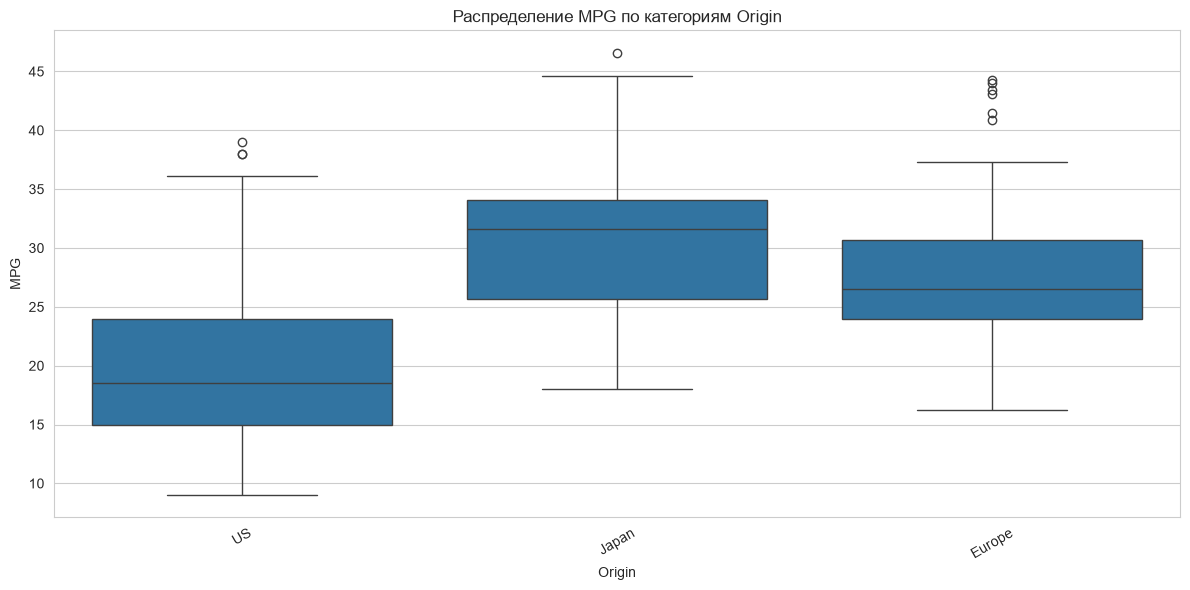

Медианы по категориям (от большей к меньшей):
Origin
Japan     31.6
Europe    26.5
US        18.5
Name: MPG, dtype: float64


In [79]:
top_categories = df[cat_column].value_counts().nlargest(5).index
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x=cat_column,
    y=coll[0],   # MPG
    order=top_categories
)

plt.xticks(rotation=30)
plt.title(f"Распределение {coll[0]} по категориям {cat_column}")
plt.xlabel(cat_column)
plt.ylabel(coll[0])

plt.tight_layout()
plt.show()

medians = df[df[cat_column].isin(top_categories)].groupby(cat_column)[coll[0]].median().sort_values(ascending=False)
print("Медианы по категориям (от большей к меньшей):")
print(medians)


### `sns.barplot()` — сравнение средних

**Что делает:**** Строит агрегированные значения, по умолчанию средние, и показывает доверительный интервал. График удобен для сравнения центральных значений, но его стоит дополнять графиком распределений.

**Синтаксис:** `sns.barplot(data=df, x=cat_column, y=column, estimator="mean")`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Датафрейм. |
| `x`, `y` | Группирующая и числовая переменные. |
| `estimator` | Функция агрегации, например `np.mean` или `np.median`. |
| `errorbar` | Тип интервала неопределённости. |

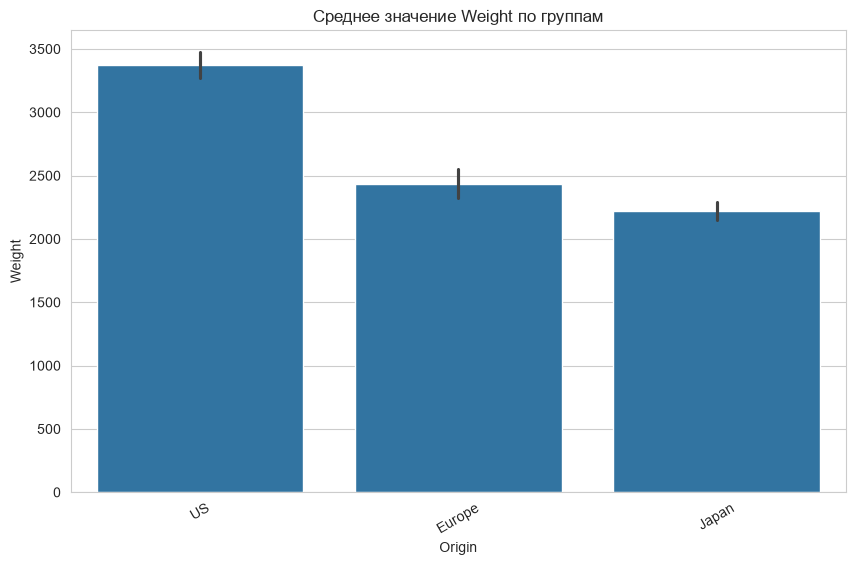

In [80]:
# Сравниваем средние значения числовой переменной по группам.
plt.figure(figsize=(10, 6))
sns.barplot(data=df, x=cat_column, y=column, estimator=np.mean, errorbar="ci")
plt.xticks(rotation=30)
plt.title(f"Среднее значение {column} по группам")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` замените среднее на медиану или другую агрегирующую функцию и сравните результат с boxplot.

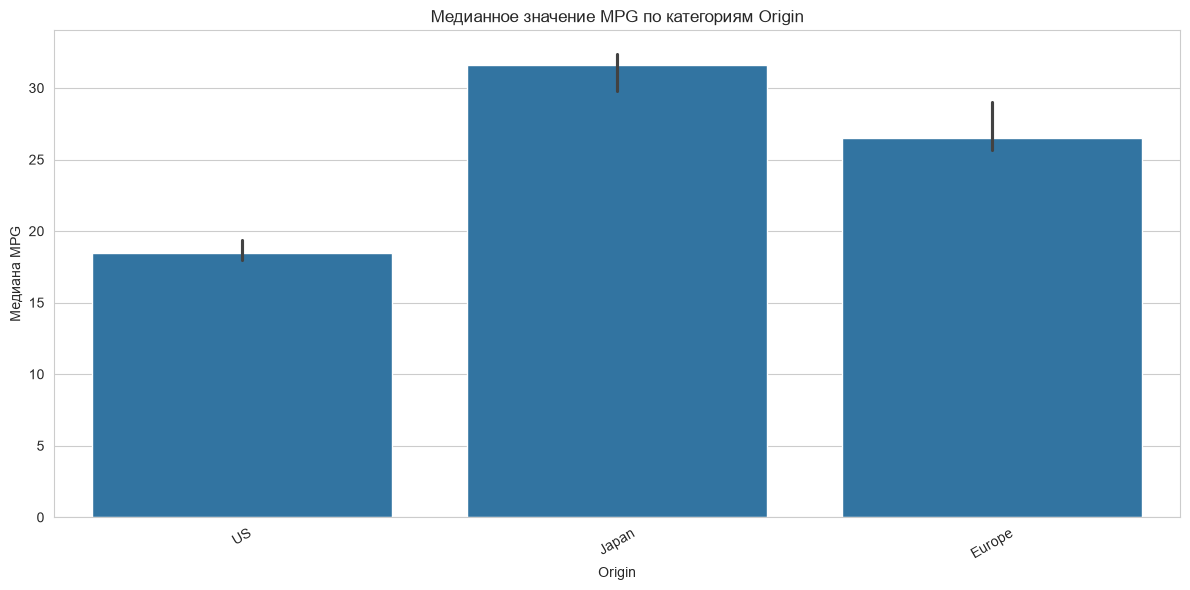

In [81]:
top_categories = df[cat_column].value_counts().nlargest(5).index

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x=cat_column,
    y=coll[0],
    order=top_categories,
    estimator=np.median,
    errorbar="ci",
)

plt.xticks(rotation=30)
plt.title(f"Медианное значение {coll[0]} по категориям {cat_column}")
plt.xlabel(cat_column)
plt.ylabel(f"Медиана {coll[0]}")
plt.tight_layout()
plt.show()


### `stats.ttest_ind()` — t-тест независимых выборок

**Что делает:**** Проверяет гипотезу о равенстве средних двух независимых групп. Нулевая гипотеза утверждает, что средние генеральных совокупностей равны.

**Синтаксис:** `stats.ttest_ind(a, b, equal_var=False, nan_policy="omit")`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `a`, `b` | Две числовые выборки. |
| `equal_var` | Считать ли дисперсии равными; `False` задаёт вариант Welch. |
| `alternative` | Альтернатива: двусторонняя или односторонняя. |

In [82]:
# Берём первые две непустые группы и выполняем t-тест Welch.
groups = [group[column].dropna() for _, group in df.groupby(cat_column) if group[column].notna().sum() > 1]
if len(groups) < 2:
    values = df[column].dropna().to_numpy()
    groups = [part for part in np.array_split(values, 2) if len(part) > 1]
result = stats.ttest_ind(groups[0], groups[1], equal_var=False, nan_policy="omit")
print(result)

TtestResult(statistic=np.float64(3.099805958376146), pvalue=np.float64(0.002403407594554454), df=np.float64(122.36735128931791))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` сформулируйте нулевую и альтернативную гипотезы, выполните тест для двух осмысленных групп и интерпретируйте p-value при уровне значимости 0.05.

In [83]:
# H0: средний расход (MPG) у двух самых частых групп происхождения одинаков.
# H1: средние MPG различаются (двусторонняя альтернатива). Уровень значимости alpha = 0.05.
num_column = coll[0]   # MPG

top_two = df[cat_column].value_counts().nlargest(2).index
group_a_name = top_two[0]
group_b_name = top_two[1]

print(f"Сравниваем группы: '{group_a_name}' и '{group_b_name}'\n")

group_a = df[df[cat_column] == group_a_name][num_column].dropna()
group_b = df[df[cat_column] == group_b_name][num_column].dropna()

t_stat, p_value = stats.ttest_ind(group_a, group_b, equal_var=False, nan_policy="omit")

print(f"Среднее {num_column}: {group_a_name} = {group_a.mean():.2f}, {group_b_name} = {group_b.mean():.2f}")
print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_value:.4g}")

alpha = 0.05
if p_value < alpha:
    print(f"\nВывод: p-value < {alpha}. Отвергаем нулевую гипотезу.")
    print("Различия в средних значениях статистически значимы.")
else:
    print(f"\nВывод: p-value >= {alpha}. Не отвергаем нулевую гипотезу.")
    print("Статистически значимых различий не обнаружено.")


Сравниваем группы: 'US' и 'Japan'

Среднее MPG: US = 20.08, Japan = 30.45
t-статистика: -13.0188
p-value: 1.011e-25

Вывод: p-value < 0.05. Отвергаем нулевую гипотезу.
Различия в средних значениях статистически значимы.


### `stats.ttest_rel()` — парный t-тест

**Что делает:**** Сравнивает средние двух зависимых выборок, например измерения одних и тех же объектов до и после воздействия. Пары должны соответствовать друг другу по строкам.

**Синтаксис:** `stats.ttest_rel(a, b, nan_policy="omit")`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `a`, `b` | Две одинаково длинные парные выборки. |
| `alternative` | Вид альтернативной гипотезы. |
| `nan_policy` | Правило обработки пропусков. |

In [84]:
# Демонстрационный парный тест для двух числовых столбцов.
paired = df[[col1, col2]].dropna()
result = stats.ttest_rel(paired[col1], paired[col2])
print(result)

TtestResult(statistic=np.float64(-70.618254512374), pvalue=np.float64(1.3343325567208299e-227), df=np.int64(399))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` проверьте, действительно ли ваши два столбца образуют парные измерения, затем выполните тест и объясните его результат.

In [85]:
# Важно: Horsepower и Weight — разные величины, а не повторные измерения одних и тех же объектов,
# поэтому это лишь демонстрация работы теста; содержательной интерпретации у такого сравнения нет.
paired = df[[col1, col2]].dropna()
result = stats.ttest_rel(paired[col1], paired[col2], nan_policy="omit")
print(result)

alpha = 0.05
if result.pvalue < alpha:
    print(f"\nВывод: p-value < {alpha}. Различия статистически значимы.")
else:
    print(f"\nВывод: p-value >= {alpha}. Статистически значимых различий нет.")


TtestResult(statistic=np.float64(-70.618254512374), pvalue=np.float64(1.3343325567208299e-227), df=np.int64(399))

Вывод: p-value < 0.05. Различия статистически значимы.


### `stats.f_oneway()` — однофакторный ANOVA

**Что делает:**** Проверяет равенство средних трёх и более независимых групп. Значимое значение p говорит, что хотя бы одна группа отличается, но само по себе не указывает какая.

**Синтаксис:** `stats.f_oneway(sample1, sample2, sample3)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `sample1`, `sample2` | Числовые выборки сравниваемых групп. |
| `nan_policy` | Обработка пропущенных значений. |
| `equal_var` | В новых версиях может задавать вариант с неодинаковыми дисперсиями. |

In [86]:
# Сравниваем первые три группы; если категорий мало, делим данные на части.
anova_groups = [group[column].dropna() for _, group in df.groupby(cat_column) if group[column].notna().sum() > 1]
if len(anova_groups) < 3:
    anova_groups = [part for part in np.array_split(df[column].dropna().to_numpy(), 3) if len(part) > 1]
result = stats.f_oneway(*anova_groups[:3])
print(result)

F_onewayResult(statistic=np.float64(116.79576918220549), pvalue=np.float64(9.794971508438515e-41))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` проведите ANOVA для трёх или более групп, укажите предпосылки метода и предложите способ поиска конкретных различий после значимого результата.

In [87]:
# H0: средний MPG одинаков во всех трёх группах происхождения; H1: хотя бы одна группа отличается.
num_column = coll[0]   # MPG

top_three = df[cat_column].value_counts().nlargest(3).index
anova_groups = [df[df[cat_column] == cat][num_column].dropna() for cat in top_three]
anova_groups = [g for g in anova_groups if len(g) > 1]

if len(anova_groups) >= 3:
    result = stats.f_oneway(*anova_groups)
    print(result)

    if result.pvalue < 0.05:
        print("\nВывод: p-value < 0.05. Различия статистически значимы (хотя бы одна группа отличается).")
    else:
        print("\nВывод: p-value >= 0.05. Статистически значимых различий не обнаружено.")
else:
    print("Недостаточно данных (меньше 3 групп с достаточным количеством наблюдений).")


F_onewayResult(statistic=np.float64(98.5417949107587), pvalue=np.float64(1.9154864184128544e-35))

Вывод: p-value < 0.05. Различия статистически значимы (хотя бы одна группа отличается).


# Раздел 4. Связь между переменными

### `df.corr()` — матрица корреляций

**Что делает:**** Вычисляет попарные коэффициенты корреляции между числовыми столбцами. Метод `pearson` измеряет линейную связь, а `spearman` основан на рангах и лучше подходит для монотонных связей.

**Синтаксис:** `df.corr(method="pearson", numeric_only=True)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `method` | `pearson`, `spearman` или `kendall`. |
| `min_periods` | Минимальное число наблюдений для расчёта. |
| `numeric_only` | Использовать только числовые столбцы. |

In [88]:
# Рассчитываем матрицу корреляций числовых переменных.
correlation_matrix = df.corr(numeric_only=True)
display(correlation_matrix)

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model
MPG,1.000000,-0.775396,-0.804203,-0.778427,-0.831741,0.420289,0.579267
Cylinders,-0.775396,1.000000,0.951787,0.844158,0.895220,-0.522452,-0.360762
Displacement,-0.804203,0.951787,1.000000,0.898326,0.932475,-0.557984,-0.381714
Horsepower,-0.778427,0.844158,0.898326,1.000000,0.866586,-0.697124,-0.424419
Weight,-0.831741,0.895220,0.932475,0.866586,1.000000,-0.430086,-0.315389
Acceleration,0.420289,-0.522452,-0.557984,-0.697124,-0.430086,1.000000,0.301992
Model,0.579267,-0.360762,-0.381714,-0.424419,-0.315389,0.301992,1.000000


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` сравните матрицы Pearson и Spearman и найдите наиболее сильную связь по модулю.

In [89]:


pearson_matrix = df.corr(method="pearson", numeric_only=True)
spearman_matrix = df.corr(method="spearman", numeric_only=True)

print("Матрица Pearson:")
display(pearson_matrix.round(2))
print("\nМатрица Spearman:")
display(spearman_matrix.round(2))

pairs = pearson_matrix.abs().unstack().reset_index()
pairs.columns = ['Переменная 1', 'Переменная 2', 'Pearson_abs']
pairs = pairs[pairs['Переменная 1'] < pairs['Переменная 2']]

spearman_pairs = spearman_matrix.abs().unstack().reset_index()
spearman_pairs.columns = ['Переменная 1', 'Переменная 2', 'Spearman_abs']

merged = pd.merge(pairs, spearman_pairs, on=['Переменная 1', 'Переменная 2'])

strongest_pearson = merged.loc[merged['Pearson_abs'].idxmax()]
strongest_spearman = merged.loc[merged['Spearman_abs'].idxmax()]

print("\nНаиболее сильная связь по Pearson (по модулю):")
print(f"{strongest_pearson['Переменная 1']} и {strongest_pearson['Переменная 2']} (r = {pearson_matrix.loc[strongest_pearson['Переменная 1'], strongest_pearson['Переменная 2']]:.3f})")

print("\nНаиболее сильная связь по Spearman (по модулю):")
print(f"{strongest_spearman['Переменная 1']} и {strongest_spearman['Переменная 2']} (rho = {spearman_matrix.loc[strongest_spearman['Переменная 1'], strongest_spearman['Переменная 2']]:.3f})")

Матрица Pearson:


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model
MPG,1.00,-0.78,-0.80,-0.78,-0.83,0.42,0.58
Cylinders,-0.78,1.00,0.95,0.84,0.90,-0.52,-0.36
Displacement,-0.80,0.95,1.00,0.90,0.93,-0.56,-0.38
Horsepower,-0.78,0.84,0.90,1.00,0.87,-0.70,-0.42
Weight,-0.83,0.90,0.93,0.87,1.00,-0.43,-0.32
Acceleration,0.42,-0.52,-0.56,-0.70,-0.43,1.00,0.30
Model,0.58,-0.36,-0.38,-0.42,-0.32,0.30,1.00



Матрица Spearman:


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model
MPG,1.00,-0.82,-0.86,-0.85,-0.87,0.44,0.57
Cylinders,-0.82,1.00,0.91,0.82,0.87,-0.49,-0.35
Displacement,-0.86,0.91,1.00,0.88,0.95,-0.51,-0.32
Horsepower,-0.85,0.82,0.88,1.00,0.88,-0.67,-0.40
Weight,-0.87,0.87,0.95,0.88,1.00,-0.42,-0.29
Acceleration,0.44,-0.49,-0.51,-0.67,-0.42,1.00,0.29
Model,0.57,-0.35,-0.32,-0.40,-0.29,0.29,1.00



Наиболее сильная связь по Pearson (по модулю):
Cylinders и Displacement (r = 0.952)

Наиболее сильная связь по Spearman (по модулю):
Displacement и Weight (rho = 0.946)


### `sns.heatmap()` — тепловая карта корреляций

**Что делает:**** Представляет матрицу числовых значений цветом и подписями. Для корреляций это компактный способ увидеть направление и силу связей между всеми парами признаков.

**Синтаксис:** `sns.heatmap(matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Матрица или датафрейм. |
| `annot` | Показывать ли значения в ячейках. |
| `cmap` | Цветовая палитра. |
| `vmin`, `vmax` | Нижняя и верхняя границы шкалы. |

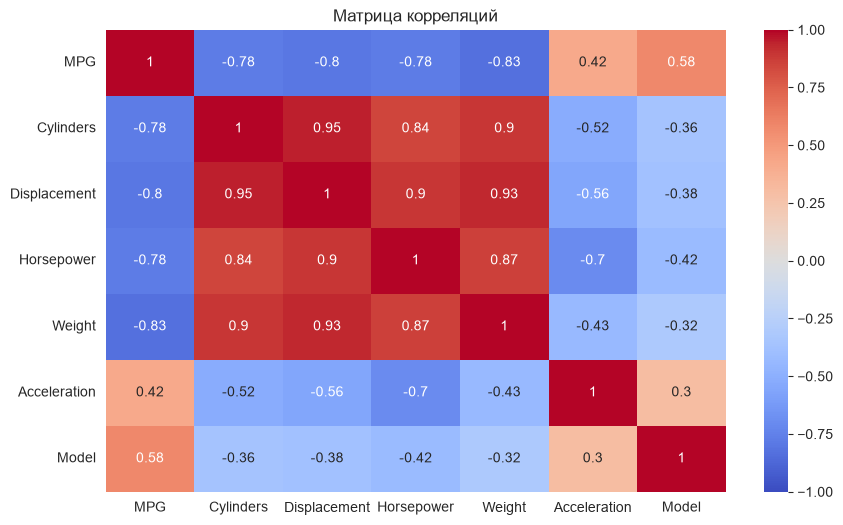

In [90]:
# Визуализируем матрицу корреляций.
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` настройте подписи и палитру тепловой карты, затем интерпретируйте одну сильную и одну слабую корреляцию.

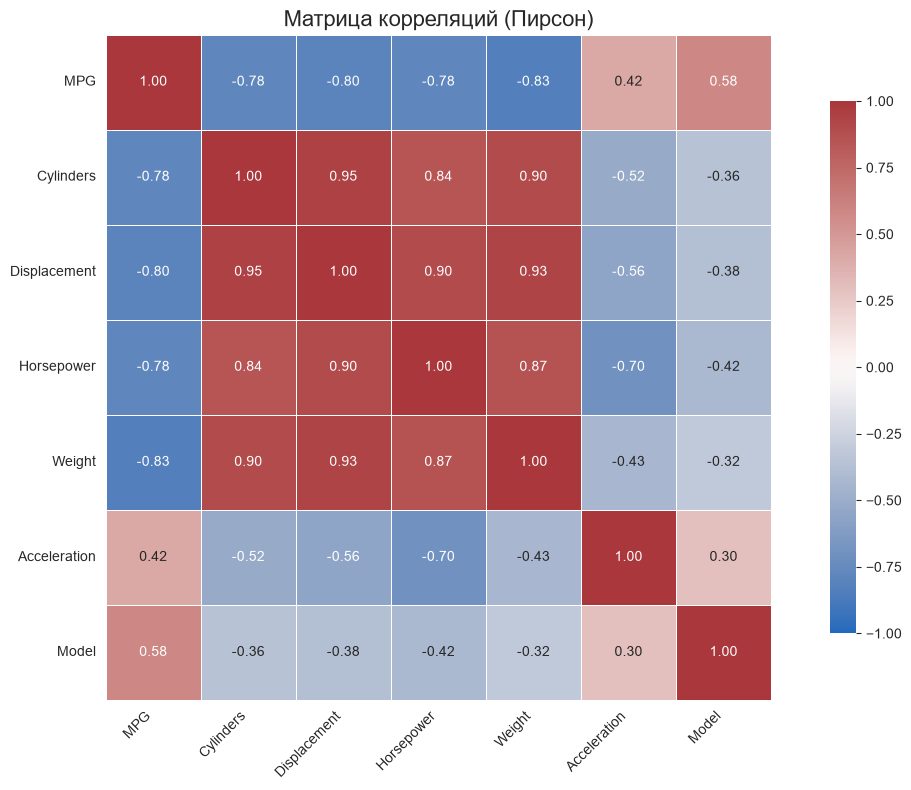

In [91]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)
plt.title("Матрица корреляций (Пирсон)", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### `sns.scatterplot()` — диаграмма рассеяния

**Что делает:**** Показывает отдельные наблюдения на плоскости двух числовых переменных. По облаку точек можно оценить направление, силу, нелинейность связи и выбросы.

**Синтаксис:** `sns.scatterplot(data=df, x=col1, y=col2, hue=cat_column)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Датафрейм. |
| `x`, `y` | Две числовые переменные. |
| `hue` | Необязательная группировка цветом. |
| `style`, `size` | Дополнительные визуальные кодирования. |

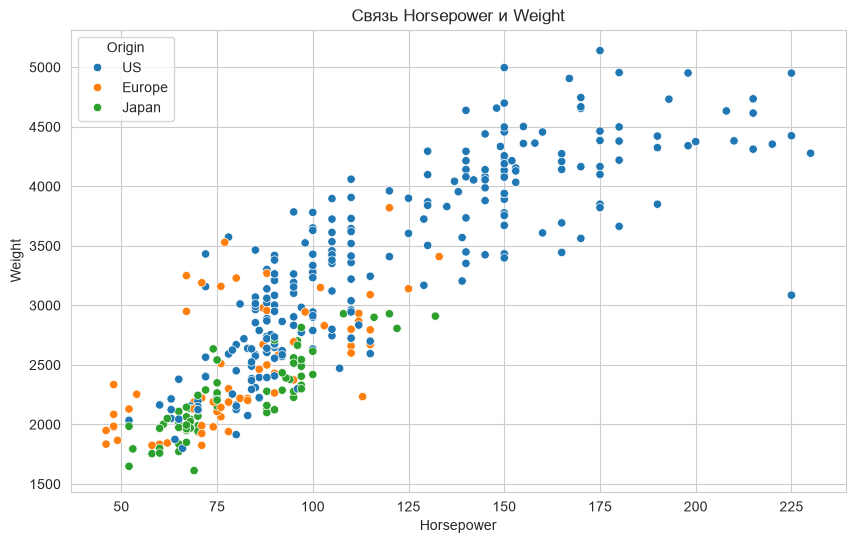

In [92]:
# Изучаем связь двух числовых столбцов.
plt.figure(figsize=(10, 6))
plot_data = df.dropna(subset=[col1, col2])
sns.scatterplot(data=plot_data, x=col1, y=col2, hue=cat_column if cat_column in plot_data else None)
plt.title(f"Связь {col1} и {col2}")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` добавьте группировку цветом или размером и опишите, меняется ли форма связи между категориями.

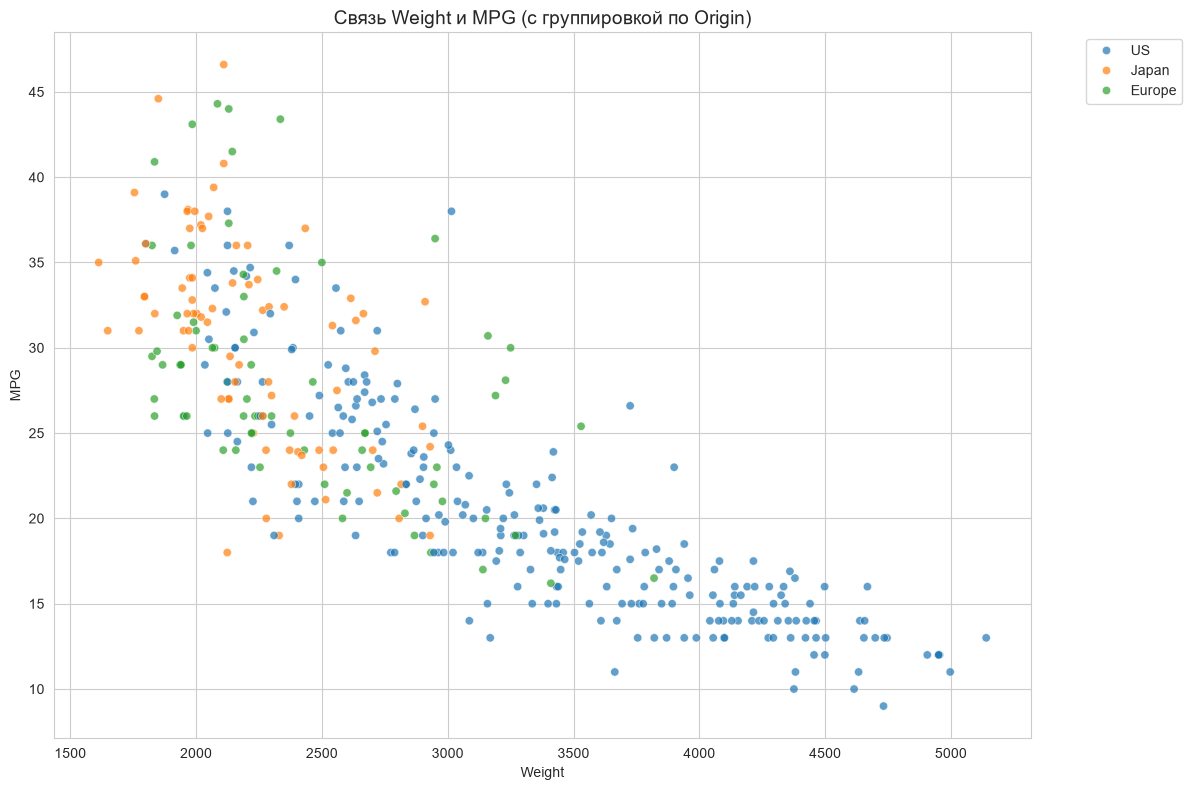

In [93]:
plot_data = df.dropna(subset=[coll[4], coll[0], cat_column])

plt.figure(figsize=(12, 8))
sns.scatterplot(data=plot_data, x=coll[4], y=coll[0], hue=cat_column, alpha=0.7)
plt.title(f"Связь {coll[4]} и {coll[0]} (с группировкой по {cat_column})", fontsize=14)
plt.xlabel(coll[4])
plt.ylabel(coll[0])
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


### `stats.pearsonr()`, `stats.spearmanr()` — коэффициенты корреляции

**Что делает:**** Возвращают коэффициент корреляции и p-value для проверки нулевой гипотезы об отсутствии связи. Pearson оценивает линейную связь, Spearman — монотонную ранговую связь.

**Синтаксис:** `stats.pearsonr(x, y)`, `stats.spearmanr(x, y)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `x`, `y` | Две числовые выборки одинаковой длины. |
| `alternative` | Вид альтернативной гипотезы. |
| `nan_policy` | Правило обработки пропусков для поддерживаемых версий SciPy. |

In [94]:
# Сравниваем линейную и ранговую корреляции.
paired = df[[col1, col2]].dropna()
print("Pearson:", stats.pearsonr(paired[col1], paired[col2]))
print("Spearman:", stats.spearmanr(paired[col1], paired[col2]))

Pearson: PearsonRResult(statistic=np.float64(0.8665862223908412), pvalue=np.float64(3.2889204315541566e-122))
Spearman: SignificanceResult(statistic=np.float64(0.8812030863572986), pvalue=np.float64(1.429766224938402e-131))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` сравните оба коэффициента, оцените их значимость и сформулируйте осторожный вывод о связи, не подменяя корреляцию причинностью.

In [95]:
col1 = coll[4]   # Weight
col2 = coll[0]   # MPG

paired = df[[col1, col2]].dropna()

pearson_r, pearson_p = stats.pearsonr(paired[col1], paired[col2])
spearman_rho, spearman_p = stats.spearmanr(paired[col1], paired[col2])

print(f"Pearson: r = {pearson_r:.4f}, p-value = {pearson_p:.4g}")
print(f"Spearman: rho = {spearman_rho:.4f}, p-value = {spearman_p:.4g}")


Pearson: r = -0.8317, p-value = 2.973e-103
Spearman: rho = -0.8749, p-value = 8.644e-127


### `sns.regplot()` — scatter с линией регрессии

**Что делает:**** Строит диаграмму рассеяния и оценивает линейную регрессионную линию с доверительным интервалом. График помогает визуально проверить линейность связи.

**Синтаксис:** `sns.regplot(data=df, x=col1, y=col2, ci=95)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `data` | Датафрейм. |
| `x`, `y` | Предиктор и отклик. |
| `ci` | Уровень доверительного интервала в процентах. |
| `order` | Степень полинома для нелинейной линии. |

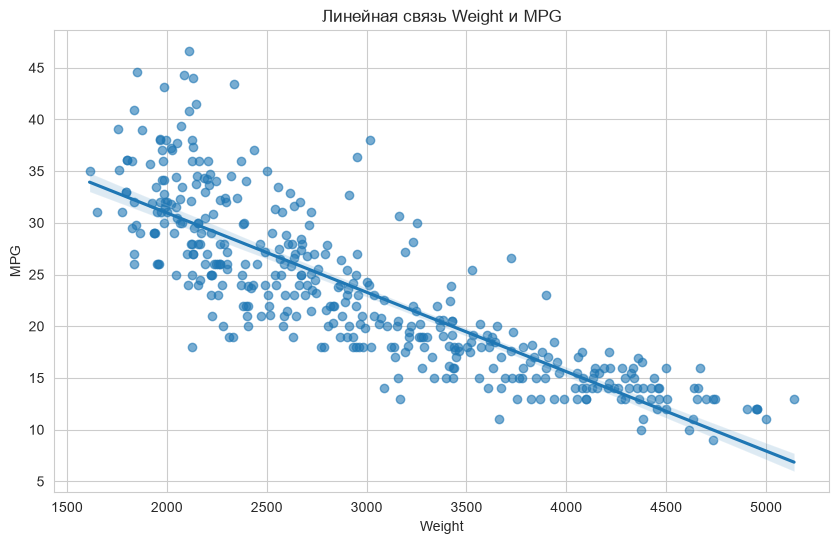

In [96]:
# Добавляем линейную регрессионную линию к облаку точек.
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x=col1, y=col2, ci=95, scatter_kws={"alpha": 0.6})
plt.title(f"Линейная связь {col1} и {col2}")
plt.show()

**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` постройте regplot для другой пары признаков и оцените, насколько линейная модель согласуется с точками.

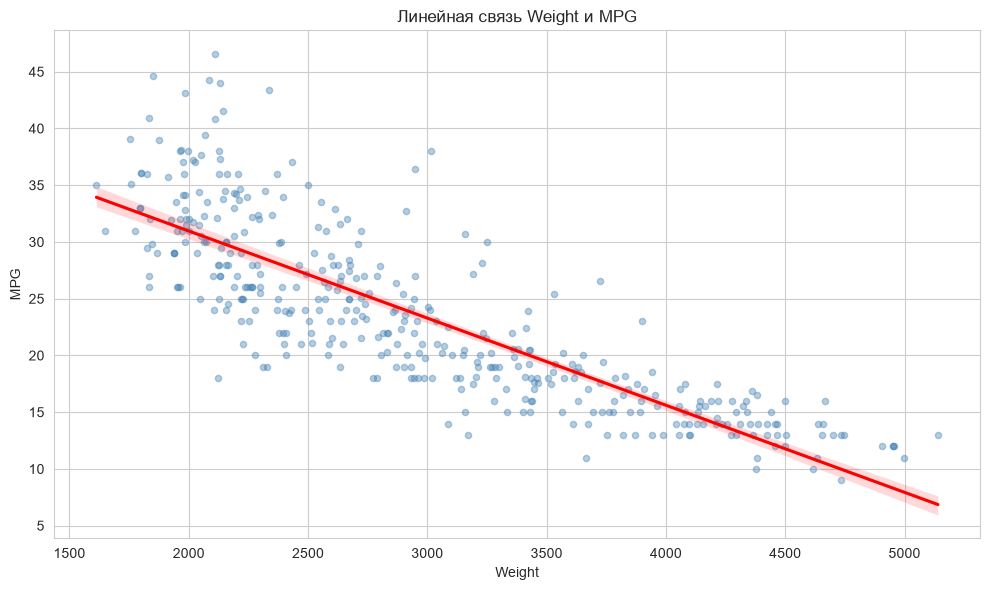

In [97]:
col1 = coll[4]   # Weight
col2 = coll[0]   # MPG

df_clean = df[[col1, col2]].dropna()

if len(df_clean) > 5000:
    df_clean = df_clean.sample(n=5000, random_state=42)

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x=col1,
    y=col2,
    ci=95,
    scatter_kws={"alpha": 0.4, "s": 20, "color": "steelblue"},
    line_kws={"color": "red"}
)

plt.title(f"Линейная связь {col1} и {col2}")
plt.xlabel(col1)
plt.ylabel(col2)
plt.tight_layout()
plt.show()


# Раздел 5. Проверка гипотез

### `stats.normaltest()` — проверка нормальности

**Что делает:**** Проверяет нормальность распределения по асимметрии и эксцессу. Нулевая гипотеза состоит в том, что выборка получена из нормального распределения; обычно нужны минимум 8 наблюдений.

**Синтаксис:** `stats.normaltest(a, nan_policy="omit")`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `a` | Наблюдаемая выборка. |
| `nan_policy` | Обработка пропусков. |
| `axis` | Ось выполнения теста. |

In [98]:
# Проверяем нормальность распределения выбранного столбца.
values = df[column].dropna().to_numpy()
if len(values) >= 8:
    print(stats.normaltest(values))
else:
    print("Для normaltest нужно не менее 8 наблюдений.")

NormaltestResult(statistic=np.float64(50.74912521148519), pvalue=np.float64(9.549210779483885e-12))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` проверьте нормальность другого столбца и сопоставьте p-value с гистограммой и Q-Q графиком.

### `stats.shapiro()` — тест Шапиро–Уилка

**Что делает:**** Проверяет гипотезу о нормальности выборки. Тест особенно популярен для небольших выборок; на практике следует учитывать размер данных и визуальную диагностику.

**Синтаксис:** `stats.shapiro(x)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `x` | Выборка числовых наблюдений. |
| `axis` | Ось вычисления. |
| `nan_policy` | Правило обработки NaN. |

In [99]:
# Запускаем тест Шапиро при допустимом размере выборки.
values = df[column].dropna().to_numpy()
if 3 <= len(values) <= 5000:
    print(stats.shapiro(values))
else:
    print("Для примера Shapiro нужна выборка размером от 3 до 5000 наблюдений.")

ShapiroResult(statistic=np.float64(0.94294859478421), pvalue=np.float64(2.207892682164017e-11))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` сравните результат Шапиро–Уилка с `normaltest()` на одной выборке и обсудите различия чувствительности тестов.

### `stats.ttest_1samp()` — одновыборочный t-тест

**Что делает:**** Проверяет, отличается ли среднее одной выборки от заданного гипотетического значения. Нулевая гипотеза: среднее равно `popmean`.

**Синтаксис:** `stats.ttest_1samp(a, popmean=value, nan_policy="omit")`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `a` | Наблюдаемая выборка. |
| `popmean` | Проверяемое среднее генеральной совокупности. |
| `alternative` | Двусторонняя или односторонняя альтернатива. |

In [100]:
# Проверяем гипотезу о среднем, равном медиане выборки.
values = df[column].dropna().to_numpy()
hypothesized_mean = df[column].median()
print(stats.ttest_1samp(values, popmean=hypothesized_mean))

TtestResult(statistic=np.float64(3.7328325457751945), pvalue=np.float64(0.0002164227023704712), df=np.int64(405))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` выберите содержательное эталонное значение, сформулируйте гипотезу и объясните, что означает p-value.

### `stats.chi2_contingency()` — хи-квадрат на независимость

**Что делает:**** Проверяет независимость двух категориальных переменных по таблице сопряжённости. Нулевая гипотеза утверждает, что распределение одной категории не зависит от другой.

**Синтаксис:** `stats.chi2_contingency(observed, correction=True)`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `observed` | Таблица наблюдаемых частот. |
| `correction` | Применять ли поправку Йейтса для таблицы 2x2. |
| `lambda_` | Вариант степенного теста при необходимости. |

In [101]:
# Создаём вторую категориальную переменную, если в CSV есть только одна.
if len(categorical_columns) >= 2:
    second_cat = categorical_columns[1]
else:
    median_value = df[column].median()
    df["_level"] = np.where(df[column] >= median_value, "high", "low")
    second_cat = "_level"

contingency = pd.crosstab(df[cat_column], df[second_cat])
print("Таблица сопряжённости:")
display(contingency)
print(stats.chi2_contingency(contingency))

Таблица сопряжённости:


_level,high,low
Origin,,
Europe,18,55
Japan,4,75
US,181,73


Chi2ContingencyResult(statistic=np.float64(128.4848110823324), pvalue=np.float64(1.2585711413331136e-28), dof=2, expected_freq=array([[ 36.5,  36.5],
       [ 39.5,  39.5],
       [127. , 127. ]]))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` выберите две категориальные переменные, постройте таблицу сопряжённости и сделайте вывод о независимости при уровне значимости 0.05.

### `stats.kstest()` — тест Колмогорова–Смирнова

**Что делает:**** Сравнивает эмпирическое распределение с заданным теоретическим распределением или сравнивает две выборки. Ниже данные стандартизируются и сопоставляются со стандартной нормалью.

**Синтаксис:** `stats.kstest(rvs, cdf, args=())`

**Аргументы:**
| Аргумент | Описание |
|---|---|
| `rvs` | Наблюдаемая выборка. |
| `cdf` | Теоретическая функция распределения или имя распределения. |
| `args` | Параметры теоретического распределения. |
| `alternative` | Направление альтернативы. |

In [102]:
# Сравниваем стандартизированные данные со стандартной нормалью.
values = df[column].dropna().to_numpy()
if len(values) > 1 and values.std(ddof=1) > 0:
    standardized = (values - values.mean()) / values.std(ddof=1)
    print(stats.kstest(standardized, "norm"))
else:
    print("Для kstest нужна вариативная выборка минимум из двух наблюдений.")

KstestResult(statistic=np.float64(0.09240882158800096), pvalue=np.float64(0.0018144052122454374), statistic_location=np.float64(-0.6746291300438022), statistic_sign=np.int8(1))


**Задание:** `# ← ЗАМЕНИТЕ НА СВОЁ:` примените KS-тест к другому столбцу или другому теоретическому распределению и сравните его вывод с тестами нормальности выше.

# Раздел 6. Итоговое задание

Проведите полный статистический анализ своего датасета. Используйте минимум по одной функции из каждого раздела:

1. Опишите структуру данных и качество загрузки.
2. Рассчитайте описательные статистики минимум для двух числовых и одной категориальной переменной.
3. Постройте не менее двух графиков распределений.
4. Сравните хотя бы две группы визуально и с помощью подходящего статистического теста.
5. Исследуйте связь двух числовых переменных корреляцией и графиком.
6. Проверьте одну статистическую гипотезу, явно записав нулевую и альтернативную гипотезы, уровень значимости и правило принятия решения.
7. Напишите итоговый вывод: какие закономерности обнаружены, насколько они надёжны и какие ограничения есть у анализа.

# ← ЗАМЕНИТЕ НА СВОЁ: добавьте собственные ячейки с расчётами и текстом вывода.

# Чек-лист самопроверки

- [ ] CSV-файл загружен из папки с ноутбуком, проверены `head()`, `info()` и `shape`.
- [ ] Определены числовые и категориальные столбцы, пропуски и возможные выбросы.
- [ ] Использованы меры центра, разброса, квартили и показатели формы распределения.
- [ ] Построены и подписаны графики распределений.
- [ ] Сравнены группы визуально и статистически, выбран подходящий тест.
- [ ] Рассчитаны корреляции и построен график связи переменных.
- [ ] Для каждой гипотезы указаны H0, H1, уровень значимости и интерпретация p-value.
- [ ] Выводы отделяют статистическую связь от причинно-следственного утверждения.
- [ ] Все задания содержат собственные результаты и объяснения.
- [ ] Все графики имеют заголовки, подписи осей и читаемые легенды.
- [ ] Ноутбук выполняется сверху вниз без ошибок.